<a href="https://colab.research.google.com/github/RaulMinutti/RaulMinutti/blob/main/linear_regresion_Raul.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- First 5 Rows of the Dataset ---
   House Size (sq ft)  Price (in $1000)
0                2126            351.94
1                2459            420.87
2                1860            337.73
3                2294            407.42
4                2130            382.91

--- Dataset Info & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   House Size (sq ft)  100 non-null    int64  
 1   Price (in $1000)    100 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 1.7 KB
None

--- Summary Statistics ---
       House Size (sq ft)  Price (in $1000)
count          100.000000        100.000000
mean          1785.760000        318.483200
std            443.093969         69.201651
min           1013.000000        163.170000
25%           1386.500000        263.227500
50%           1810.000000        326.130000

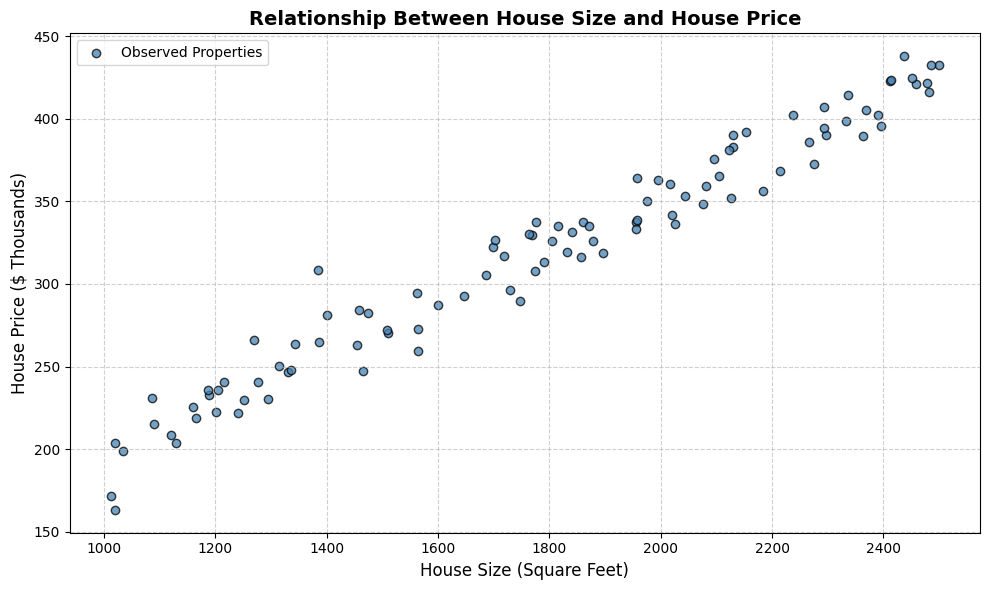


--- Trained Linear Regression Model Parameters ---
Intercept (b0): 40.6920
Slope / Coefficient (b1): 0.1552
Regression Equation: Price = 40.6920 + (0.1552 * House_Size)

--- Test Set Predictions ---
 House Size (sq ft)  Actual Price ($k)  Predicted Price ($k)  Residual Error ($k)
               1995             363.10                350.30                12.80
               1600             287.51                289.00                -1.49
               1205             235.85                227.70                 8.15
               1831             319.13                324.84                -5.71
               2267             386.20                392.51                -6.31
               1189             233.07                225.21                 7.86
               1385             308.33                255.63                52.70
               1729             296.14                309.01               -12.87
               1330             246.83                247.09  

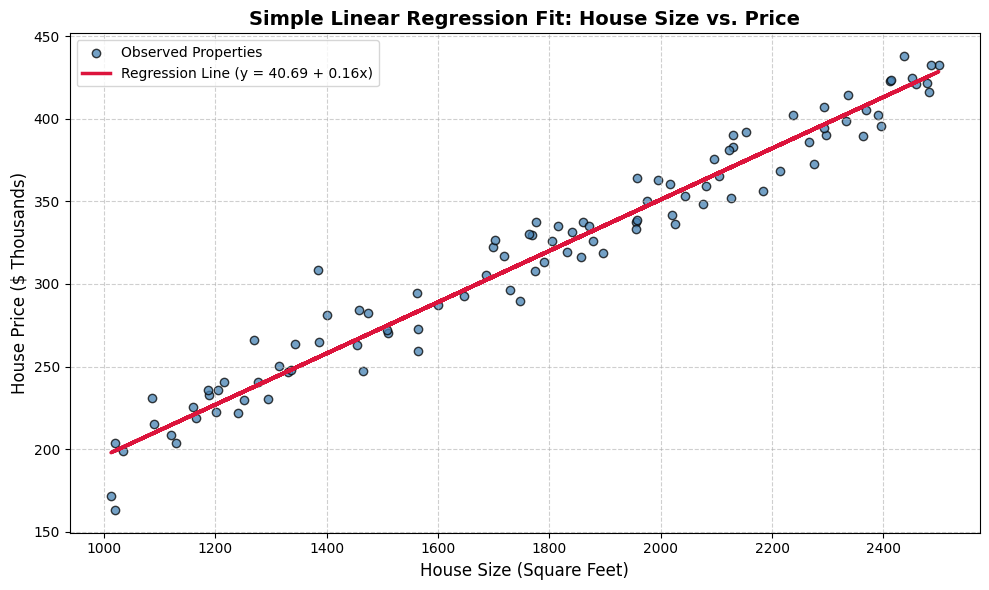

In [2]:
# ==============================================================================

# Simple Linear Regression: House Size vs. House Price

# Tasks 1, 2, and 3 Implementation

# ==============================================================================



# Import required libraries

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_squared_error, r2_score



# ==============================================================================

# TASK 1: Data Exploration

# ==============================================================================



# 1a. Load the dataset and inspect its structure

# Ensure 'house_prices.csv' is in your working directory

df = pd.read_csv('house_prices.csv')



print("--- First 5 Rows of the Dataset ---")

print(df.head())



print("\n--- Dataset Info & Data Types ---")

print(df.info())



print("\n--- Summary Statistics ---")

print(df.describe())



print("\n--- Missing Values Check ---")

print(df.isnull().sum())



# Dynamically identify the feature (size) and target (price) columns

# (Handles variations such as 'Size', 'House_Size', 'Square_Feet' and 'Price', 'House_Price')

size_col = [col for col in df.columns if 'size' in col.lower() or 'sq' in col.lower()][0]

price_col = [col for col in df.columns if 'price' in col.lower()][0]



# 1b. Plot a scatterplot of the data to visualize the relationship between variables

plt.figure(figsize=(10, 6))

plt.scatter(df[size_col], df[price_col], color='steelblue', alpha=0.75, edgecolors='k', label='Observed Properties')

plt.title('Relationship Between House Size and House Price', fontsize=14, fontweight='bold')

plt.xlabel('House Size (Square Feet)', fontsize=12)

plt.ylabel('House Price ($ Thousands)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.6)

plt.legend()

plt.tight_layout()



# Save the scatterplot as a .jpg file (for Submission Item #2)

plt.savefig('house_size_vs_price_scatterplot.jpg', dpi=300, format='jpg')

plt.show()



# ==============================================================================

# TASK 2: Model Building

# ==============================================================================



# 2a. Define the feature matrix X (house size) and target vector y (price)

# Reshape X to a 2D array as required by scikit-learn

X = df[[size_col]].values

y = df[price_col].values



# Split the dataset into training (80%) and testing (20%) sets for unbiased evaluation

X_train, X_test, y_train, y_test = train_test_split(

    X, y, test_size=0.20, random_state=42

)



# 2b. Initialize and train the Simple Linear Regression model using scikit-learn

model = LinearRegression()

model.fit(X_train, y_train)



# Extract model parameters (Intercept and Slope/Coefficient)

intercept = model.intercept_

slope = model.coef_[0]



print("\n--- Trained Linear Regression Model Parameters ---")

print(f"Intercept (b0): {intercept:.4f}")

print(f"Slope / Coefficient (b1): {slope:.4f}")

print(f"Regression Equation: Price = {intercept:.4f} + ({slope:.4f} * House_Size)")



# Generate predictions on the test dataset

y_pred = model.predict(X_test)



# Display actual vs. predicted values for the test set

results_df = pd.DataFrame({

    'House Size (sq ft)': X_test.flatten(),

    'Actual Price ($k)': y_test,

    'Predicted Price ($k)': np.round(y_pred, 2),

    'Residual Error ($k)': np.round(y_test - y_pred, 2)

})

print("\n--- Test Set Predictions ---")

print(results_df.to_string(index=False))



# ==============================================================================

# TASK 3: Model Evaluation

# ==============================================================================



# 3a. Calculate the Mean Squared Error (MSE) and R-squared (R2) on the test set

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)



print("\n--- Model Performance Evaluation (Test Set) ---")

print(f"Mean Squared Error (MSE): {mse:.4f}")

print(f"Root Mean Squared Error (RMSE): {rmse:.4f} ($ Thousands)")

print(f"Coefficient of Determination (R^2): {r2:.4f}")



# Optional: Plot the regression line over the full dataset for visual verification

plt.figure(figsize=(10, 6))

plt.scatter(X, y, color='steelblue', alpha=0.75, edgecolors='k', label='Observed Properties')

plt.plot(X, model.predict(X), color='crimson', linewidth=2.5, label=f'Regression Line (y = {intercept:.2f} + {slope:.2f}x)')

plt.title('Simple Linear Regression Fit: House Size vs. Price', fontsize=14, fontweight='bold')

plt.xlabel('House Size (Square Feet)', fontsize=12)

plt.ylabel('House Price ($ Thousands)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.6)

plt.legend()

plt.tight_layout()

plt.savefig('house_size_regression_fit.jpg', dpi=300, format='jpg')

plt.show()